In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("most_used_beauty_cosmetics_products_extended.csv")

print("Dataset Loaded Successfully")
display(df.head())

Dataset Loaded Successfully


,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (15000, 14)

Column Names:
Index(['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Price_USD',
       'Rating', 'Number_of_Reviews', 'Product_Size', 'Skin_Type',
       'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free',
       'Country_of_Origin'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Product_Name       15000 non-null  str    
 1   Brand              15000 non-null  str    
 2   Category           15000 non-null  str    
 3   Usage_Frequency    15000 non-null  str    
 4   Price_USD          15000 non-null  float64
 5   Rating             15000 non-null  float64
 6   Number_of_Reviews  15000 non-null  int64  
 7   Product_Size       15000 non-null  str    
 8   Skin_Type          15000 non-null  str    
 9   Gender_Target      15000 non-null  st

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
count,15000,15000,15000,15000,15000.000000,15000.000000,15000.000000,15000,15000,15000,15000,15000,15000,15000
unique,120,40,24,4,NaN,NaN,NaN,6,5,3,6,7,2,8
top,Super Setting Spray,Milk Makeup,Serum,Occasional,NaN,NaN,NaN,100ml,Combination,Male,Jar,Retinol,False,Italy
freq,154,426,710,3794,NaN,NaN,NaN,2551,3060,5017,2567,2180,7592,1942
mean,NaN,NaN,NaN,NaN,80.134108,3.002327,5014.231333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,40.402983,1.168029,2855.665464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,10.000000,1.000000,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,45.480000,2.000000,2562.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,80.040000,3.000000,5002.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,114.760000,4.000000,7497.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Missing Values:
Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64

Missing Value Percentage:
Product_Name         0.0
Brand                0.0
Category             0.0
Usage_Frequency      0.0
Price_USD            0.0
Rating               0.0
Number_of_Reviews    0.0
Product_Size         0.0
Skin_Type            0.0
Gender_Target        0.0
Packaging_Type       0.0
Main_Ingredient      0.0
Cruelty_Free         0.0
Country_of_Origin    0.0
dtype: float64


In [5]:
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

print("Duplicates Remaining:", df.duplicated().sum())

Duplicate Rows: 0
Dataset Shape After Removing Duplicates: (15000, 14)
Duplicates Remaining: 0


In [6]:
df_test = df.copy()

df_test.loc[0, "Price_USD"] = np.nan
df_test.loc[1, "Rating"] = np.nan

print("Missing Values Before Handling:")
print(df_test[["Price_USD", "Rating"]].isnull().sum())

df_test["Price_USD"] = df_test["Price_USD"].fillna(
    df_test["Price_USD"].median()
)

df_test["Rating"] = df_test["Rating"].fillna(
    df_test["Rating"].median()
)

print("\nMissing Values After Handling:")
print(df_test[["Price_USD", "Rating"]].isnull().sum())

Missing Values Before Handling:
Price_USD    1
Rating       1
dtype: int64

Missing Values After Handling:
Price_USD    0
Rating       0
dtype: int64


In [7]:
df_test = df.copy()

df_test = pd.concat([df_test, df_test.iloc[[0]]], ignore_index=True)

print("Rows Before Removing Duplicate:", len(df_test))
print("Duplicate Rows:", df_test.duplicated().sum())

df_test = df_test.drop_duplicates()

print("\nRows After Removing Duplicate:", len(df_test))
print("Duplicate Rows Remaining:", df_test.duplicated().sum())

Rows Before Removing Duplicate: 15001
Duplicate Rows: 1

Rows After Removing Duplicate: 15000
Duplicate Rows Remaining: 0


In [8]:
print("Invalid Prices:")
print((df["Price_USD"] <= 0).sum())

print("\nInvalid Ratings:")
print((~df["Rating"].between(1, 5)).sum())

print("\nNegative Review Counts:")
print((df["Number_of_Reviews"] < 0).sum())

Invalid Prices:
0

Invalid Ratings:
0

Negative Review Counts:
0


In [9]:
categorical_cols = [
    "Brand",
    "Category",
    "Usage_Frequency",
    "Product_Size",
    "Skin_Type",
    "Gender_Target",
    "Packaging_Type",
    "Main_Ingredient",
    "Cruelty_Free",
    "Country_of_Origin"
]

for col in categorical_cols:
    df[col] = df[col].astype("string").str.strip()

print("Categorical Data Standardized")

display(df[categorical_cols].head())

Categorical Data Standardized


,Brand,Category,Usage_Frequency,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Drunk Elephant,Blush,Weekly,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Laura Mercier,Makeup Remover,Occasional,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Natasha Denona,Highlighter,Daily,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Ilia Beauty,Face Mask,Occasional,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Charlotte Tilbury,Highlighter,Occasional,100ml,Oily,Female,Compact,Glycerin,False,Germany


Lower Limit: -58.440000000000005
Upper Limit: 218.68
Number of Price Outliers: 0


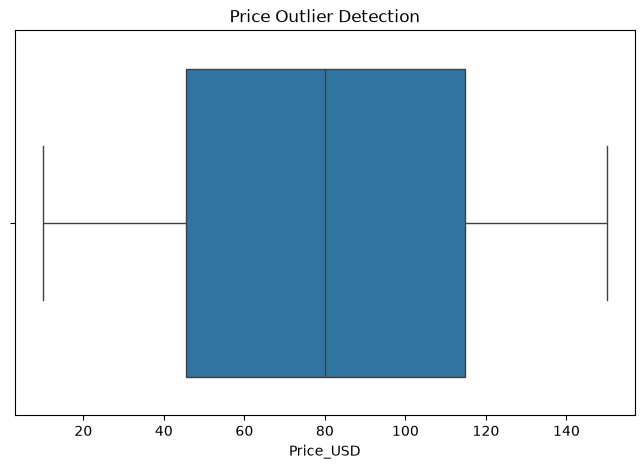

In [10]:
Q1 = df["Price_USD"].quantile(0.25)
Q3 = df["Price_USD"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Price_USD"] < lower_limit) |
    (df["Price_USD"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Price Outliers:", len(outliers))

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Price_USD"])
plt.title("Price Outlier Detection")
plt.show()

In [11]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df[["Price_Normalized", "Reviews_Normalized"]] = scaler.fit_transform(
    df[["Price_USD", "Number_of_Reviews"]]
)

print("Normalized Data:")
display(df[
    ["Price_USD", "Price_Normalized",
     "Number_of_Reviews", "Reviews_Normalized"]
].head())

Normalized Data:


,Price_USD,Price_Normalized,Number_of_Reviews,Reviews_Normalized
0,67.85,0.413244,686,0.063731
1,116.43,0.760269,5483,0.545939
2,90.84,0.577470,5039,0.501307
3,55.17,0.322666,6202,0.618215
4,140.56,0.932638,297,0.024628


In [12]:
print("FINAL DATASET VALIDATION")

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nInvalid Prices:")
print((df["Price_USD"] <= 0).sum())

print("\nInvalid Ratings:")
print((~df["Rating"].between(1, 5)).sum())

print("\nNegative Reviews:")
print((df["Number_of_Reviews"] < 0).sum())

print("\nNormalized Column Ranges:")
print(df[["Price_Normalized", "Reviews_Normalized"]].agg(["min", "max"]))

display(df.head())

FINAL DATASET VALIDATION

Dataset Shape:
(15000, 16)

Missing Values:
Product_Name          0
Brand                 0
Category              0
Usage_Frequency       0
Price_USD             0
Rating                0
Number_of_Reviews     0
Product_Size          0
Skin_Type             0
Gender_Target         0
Packaging_Type        0
Main_Ingredient       0
Cruelty_Free          0
Country_of_Origin     0
Price_Normalized      0
Reviews_Normalized    0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0

Invalid Prices:
0

Invalid Ratings:
0

Negative Reviews:
0

Normalized Column Ranges:
     Price_Normalized  Reviews_Normalized
min               0.0                 0.0
max               1.0                 1.0


,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin,Price_Normalized,Reviews_Normalized
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia,0.413244,0.063731
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK,0.760269,0.545939
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy,0.577470,0.501307
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea,0.322666,0.618215
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany,0.932638,0.024628
